In [64]:
#!/usr/bin/env python3
# -*- coding: utf-8 -*-

#  Copyright (c) 2021 - 2022.  FlexibleLecture@Linkedin
#  All rights reserved.

# Created By  : FlexibleLecture@Linkedin
# Created Date: 1/27/2022
# version ='1.0'

# Demo: Further Experiments on Solving A Family of SDP by Barrier Method

In book-convex-2004, the barrier method was used to solve a family of SDP problems
\begin{equation}
\begin{array}{rl}
\text{minimize} & 1^Tx \\
\text{subject to} & A+diag(x) \succeq 0 \\
\end{array}
\end{equation}
where $x\in R^n, A\in S^n$.

An upper bound of the optimal value is
\begin{equation}
\bar{p} = -min(eig(A)) * n
\end{equation}

and a lower bound of the optimal value is

\begin{equation}
p_* = -max(eig(A)) * n
\end{equation}


The above SDP problem can be rewritten into the standard form in the prior demo

\begin{equation}
\begin{array}{rl}
\text{minimize} & c^Tx \\
\text{subject to} & F(x)=\displaystyle{\sum_{i=1}^{n}}x_iF_i+G \preceq 0 \\
\end{array}
\end{equation}

where 
\begin{equation}
\begin{array}{rcl}
c & = & \mathbf{1}_{n\times 1} \\
F_i & : & [F_i]_{k,l}=\left\{\begin{array}{ll}
-1 & \text{if } k=l=i \\
0 & otherwise \\
\end{array} \right. \\
G & = & -A\in \mathbf{S}^n \\ 
\end{array}
\end{equation}


Then the variation of the phase I feasibility problem can be applied to get a strict feasible point as the start point for the barrier method. Note that when solving the phase I feasibility problem, the centering step can be stopped whenever $s$ has reached below zero.

\begin{equation}
\begin{array}{rl}
\text{minimize} & s \\
\text{subject to} & R(x,s)=\displaystyle{\sum_{i=1}^{n}}x_iF_i+G-sI \preceq 0 \\
& s\geq s_{min} \\
& x_i^2 \leq M^2, i=1,2,...,n \\
\end{array}
\end{equation}

In the first experiment, the problem with $\mu=20$ and $n=5, 50, 100, 200$ are simulated. Attached is the simulation result showing the number of iterations in reach the optimal values, excluding the iterations in the phase I feasibility problem.

In the second experiment, the problem with $n=[10,20,...,90]$ are simulated with a number of times. 

In [65]:
import warnings
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator
from scipy.stats import ortho_group

In [66]:
def is_pos_def(x):
    """
    utility function, check whether matrix x is positive definite
    :param x:
    :return:
    """
    return np.all(np.linalg.eigvals(x) > 0)


def is_neg_def(x):
    """
    utility function, check whether matrix x is negative definite
    :param x:
    :return:
    """
    return np.all(np.linalg.eigvals(x) < 0)


def is_semi_pos_def(x):
    """
    utility function, check whether matrix x is semi-positive definite
    :param x:
    :return:
    """
    return np.all(np.linalg.eigvals(x) >= 0)


def is_semi_neg_def(x):
    """
    utility function, check whether matrix x is semi-negative definite
    :param x:
    :return:
    """
    return np.all(np.linalg.eigvals(x) <= 0)

$f_0(x)=c^Tx$

$\nabla f_0(x)=c$

$\nabla^2 f_0(x)=0$

In [67]:
def my_f_0(x, c, F, G):
    """
    $f_0(x)=c^Tx$
    :param x:
    :param c:
    :param F:
    :param G:
    :return:
    """
    return (c.T @ x).item()


def my_f_0_feasible(x, c, F, G):
    return True


def my_gradient_f_0(x, c, F, G):
    """
    $\nabla f_0(x)=c$
    :param x:
    :param c:
    :param F:
    :param G:
    :return:
    """
    return c


def my_hessian_f_0(x, c, F, G):
    """
    $\nabla^2 f_0(x)=0$
    :param x:
    :param c:
    :param F:
    :param G:
    :return:
    """
    return np.zeros((len(x), len(x)))

$\phi(x)=-\log det(-F(x))$

If overflow occurs in calculating $det(-F(x))$,
then $F(x)$ will be scaled up by 2 or down by 0.5 recursively,
until no overflow occurs.

It requires $F(x)\succ 0$.

The gradient of $\phi(x)$,
   
   \begin{equation}
    \begin{array}{rcl}
    \nabla\phi(x) & = & \left[\begin{array}{c}
    \vdots \\
    tr(-F(x)^{-1}F_i) \\
    \vdots \\
    \end{array} \right]
    \end{array}
    \end{equation}

The Hessian of $\phi(x)$
    $$
    \begin{array}{rcl}
    \nabla^2\phi(x)_{i,j} & = & \displaystyle{\lim_{\Delta x_j\rightarrow 0}}\dfrac{tr(-F(x+\Delta x_j \vec{e}_j)^{-1}F_i) - tr(-F(x)^{-1}F_i)}{\Delta x_j} \\
    & = & tr((-F(x)^{-1})F_j(-F(x)^{-1})F_i) \\
    \end{array}
    $$

In [68]:
def my_phi(x, c, F, G):
    """
    $\phi(x)=-\log det(-F(x))$
    If overflow occurs in calculating $det(-F(x))$,
    then $F(x)$ will be scaled up by 2 or down by 0.5 recursively,
    until no overflow occurs.
    :param x:
    :param c:
    :param F:
    :param G:
    :return:
    """
    n = len(x)
    Fx = G.copy()
    for i in range(n):
        Fx += x[i][0] * F[i]
    # print('Debug: trace(-Fx)={}'.format(np.trace(-Fx)))

    with warnings.catch_warnings():
        warnings.filterwarnings('ignore')
        phi = -1 * np.log(np.linalg.det(-Fx))
        if phi < 0 and np.isinf(phi):
            scale = 0.5
            while scale >= 2 ** -30:
                scaled_Fx = scale * Fx
                phi = -1 * (np.log(np.linalg.det(-scaled_Fx)) - n * np.log(scale))
                if not np.isinf(phi):
                    break
                scale *= 1 / 2
            if np.isinf(phi):
                raise RuntimeError('phi = -inf')
            return phi
        elif phi > 0 and np.isinf(phi):
            scale = 2
            while scale <= 2 ** 30:
                scaled_Fx = scale * Fx
                phi = -1 * (np.log(np.linalg.det(-scaled_Fx)) - n * np.log(scale))
                if not np.isinf(phi):
                    break
                scale *= 2
            if np.isinf(phi):
                raise RuntimeError('phi = +inf')
            return phi
        else:
            return phi


def my_phi_feasible(x, c, F, G):
    """
    It requires $F(x)\succ 0 $
    :param x:
    :param c:
    :param F:
    :param G:
    :return:
    """
    n = len(x)
    Fx = G.copy()
    for i in range(n):
        Fx += x[i][0] * F[i]
    return is_semi_neg_def(Fx)


def my_gradient_phi(x, c, F, G):
    """
    gradient of $\phi(x)$
    \begin{equation}
    \begin{array}{rcl}
    \nabla\phi(x) & = & \left[\begin{array}{c}
    \vdots \\
    tr(-F(x)^{-1}F_i) \\
    \vdots \\
    \end{array} \right]
    \end{array}
    \end{equation}
    :param x:
    :param c:
    :param F:
    :param G:
    :return:
    """
    n = len(x)
    Fx = G.copy()
    for i in range(n):
        Fx += x[i][0] * F[i]
    g = [np.trace(-1 * np.linalg.inv(Fx) @ F[i]) for i in range(n)]
    return np.reshape(np.array(g), (n, 1))


def my_hessian_phi(x, c, F, G):
    """
    Hessian of $\phi(x)$
    $$
    \begin{array}{rcl}
    \nabla^2\phi(x)_{i,j} & = & \displaystyle{\lim_{\Delta x_j\rightarrow 0}}\dfrac{tr(-F(x+\Delta x_j \vec{e}_j)^{-1}F_i) - tr(-F(x)^{-1}F_i)}{\Delta x_j} \\
    & = & tr((-F(x)^{-1})F_j(-F(x)^{-1})F_i) \\
    \end{array}
    $$
    :param x:
    :param c:
    :param F:
    :param G:
    :return:
    """
    n = len(x)
    Fx = G.copy()
    for i in range(n):
        Fx += x[i][0] * F[i]

    minus_inv_Fx = -1 * np.linalg.inv(Fx)
    H = np.zeros((n, n))
    for i in range(n):
        for j in range(n):
            H[i][j] = np.trace(minus_inv_Fx @ F[j] @ minus_inv_Fx @ F[i])

    if not is_pos_def(H):
        raise RuntimeError('Hessian should be positive.')
    return H

$f(x)=tf_0(x)+\phi(x)$

$\nabla f(x)=t\nabla f_0(x)+\nabla \phi(x)$

$\nabla^2 f(x)=t\nabla^2 f_0(x)+\nabla^2 \phi(x)$

In [69]:
def my_f(x, t, c, F, G):
    """
    $f(x)=tf_0(x)+\phi(x)$
    :param x:
    :param t:
    :param c:
    :param F:
    :param G:
    :return:
    """
    return t * my_f_0(x, c, F, G) + my_phi(x, c, F, G)


def my_f_feasible(x, t, c, F, G):
    return my_f_0_feasible(x, c, F, G) and my_phi_feasible(x, c, F, G)


def my_gradient_f(x, t, c, F, G):
    """
    $\nabla f(x)=t\nabla f_0(x)+\nabla \phi(x)$
    :param x:
    :param t:
    :param c:
    :param F:
    :param G:
    :return:
    """
    return t * my_gradient_f_0(x, c, F, G) + my_gradient_phi(x, c, F, G)


def my_hessian_f(x, t, c, F, G):
    """
    $\nabla^2 f(x)=t\nabla^2 f_0(x)+\nabla^2 \phi(x)$
    :param x:
    :param t:
    :param c:
    :param F:
    :param G:
    :return:
    """
    return t * my_hessian_f_0(x, c, F, G) + my_hessian_phi(x, c, F, G)

Calculation of the Newton step: $\Delta x_{nt}=-\nabla^2f(x)^{-1}\nabla f(x)$

In [70]:
def my_newton_step_decrement(x, args):
    """
    Calculation of the Newton step: $\Delta x_{nt}=-\nabla^2f(x)^{-1}\nabla f(x)$
    :param x:
    :param args:
    :return:
    """
    gradient = my_gradient_f(x, *args)
    hessian = my_hessian_f(x, *args)
    KKT = hessian
    residual = gradient
    cond = np.linalg.cond(KKT)
    if cond < 1e30:
        x_nt = np.linalg.inv(KKT) @ (-1 * residual)
        decrement_1 = -1 * gradient.T @ x_nt
        decrement_2 = x_nt.T @ hessian @ x_nt
        if not np.allclose(decrement_1, decrement_2):
            print('Warning: Quantization error detected in the two ways in calculating the decrement')
        if decrement_1 < 0:
            print('Warning: Quantization error detected as the Newton step x_{nt} is not in the descent direction')

        decrement = decrement_2
        return x_nt, decrement.item()
    else:
        raise RuntimeError('the KKT system is not invertible!')

Backtracking line search implementation, see to Algorithm 9.2 in the textbook

In [71]:
def backtracking_line_search(f, df, x, delta_x, alpha, beta, args):
    """
    Backtracking line search implementation, see to Algorithm 9.2 in the textbook
    :param f:
    :param df:
    :param x:
    :param delta_x:
    :param alpha:
    :param beta:
    :param args:
    :return:
    """
    s = 1
    while (not my_f_feasible(x + delta_x * s, *args)) \
            or f(x + delta_x * s, *args) > f(x, *args) + alpha * s * ((df(x, *args).T @ delta_x).item()):
        s = beta * s
    return s

The centering step, to compute $x^*(t)$ by minimizing $tf_0+\phi$, starting from x0, with the parameters,
    $\alpha$, $\beta$ in the backtracking line search method.

In [72]:
def centering_step(x0, epsilon, alpha, beta, barrier_t, c, F, G):
    """
    The centering step, to compute $x^*(t)$ by minimizing $tf_0+\phi$, starting from x0, with the parameters,
    $\alpha$, $\beta$ in the backtracking line search method.
    :param x0:
    :param epsilon:
    :param alpha:
    :param beta:
    :param barrier_t:
    :param c:
    :param F:
    :param G:
    :return:
    """
    x = x0
    args = (barrier_t, c, F, G)
    x_nt, decrement = my_newton_step_decrement(x, args)

    line_search_steps = []
    fx = [my_f(x, *args)]
    decrements = [decrement]
    iteration = 1
    while decrement / 2 > epsilon:
        step = backtracking_line_search(my_f, my_gradient_f, x, x_nt, alpha, beta, args)
        x_next = x + step * x_nt
        x = x_next
        x_nt, decrement = my_newton_step_decrement(x, args)

        # print(r'Info: iteration={}, barrier_t={}, decrement={}, line search step ={}'.format(iteration, barrier_t,
        #                                                                                      decrement, step))
        line_search_steps.append(step)
        fx.append(my_f(x, *args))
        decrements.append(decrement)

        iteration = iteration + 1

    n_iter = iteration
    xt = x
    return xt, n_iter, fx, decrements, line_search_steps

 The logarithmic barrier function is
    \begin{equation}
    \begin{array}{rcl}
    \phi_{feas}(x,s) & = & \phi_{1}(x,s) + \phi_{2}(x,s) + \phi_{3}(x,s) \\
    \end{array}
    \end{equation}
    where
    \begin{equation}
    \begin{array}{rcl}
    \phi_1(x,s) & = & -\log det(-R(x,s)) \\
    \phi_2(x,s) & = & -\log (s-s_{min}) \\
    \phi_3(x,s) & = & -\displaystyle{\sum_{i=1}^n} \log (M^2-x_i^2) \\
    \end{array}
    \end{equation}
    
The gradient of the logarithmic barrier function is
    \begin{equation}
    \begin{array}{rcl}
    \nabla_{feas}(x,s) & = & \nabla \phi_{1}(x,s) + \nabla \phi_{2}(x,s) + \nabla \phi_3(x,s) \\
    \end{array}
    \end{equation}

 The hessian of the logarithmic barrier function is
    \begin{equation}
    \begin{array}{rcl}
    \nabla^2_{feas}(x,s) & = & \nabla^2 \phi_{1}(x,s) + \nabla^2 \phi_{2}(x,s) + \nabla^2 \phi_3(x,s) \\
    \end{array}
    \end{equation}


In [73]:
def my_phi_phase_I(xs, c_hat, F_hat, G_hat, s_min, x_bound):
    """
    The logarithmic barrier function is
    \begin{equation}
    \begin{array}{rcl}
    \phi_{feas}(x,s) & = & \phi_{1}(x,s) + \phi_{2}(x,s) + \phi_{3}(x,s) \\
    \end{array}
    \end{equation}
    where
    \begin{equation}
    \begin{array}{rcl}
    \phi_1(x,s) & = & -\log det(-R(x,s)) \\
    \phi_2(x,s) & = & -\log (s-s_{min}) \\
    \phi_3(x,s) & = & -\displaystyle{\sum_{i=1}^n} \log (M^2-x_i^2) \\
    \end{array}
    \end{equation}
    :param xs:
    :param c_hat:
    :param F_hat:
    :param G_hat:
    :param s_min:
    :param x_bound:
    :return:
    """
    n_hat = len(xs)
    Fx_hat = G_hat.copy()
    for i in range(n_hat):
        Fx_hat += xs[i][0] * F_hat[i]

    with warnings.catch_warnings():
        warnings.filterwarnings('ignore')
        phi_1 = -1 * np.log(np.linalg.det(-Fx_hat))

        if phi_1 < 0 and np.isinf(phi_1):
            scale = 0.5
            while scale >= 2 ** -30:
                scaled_Fx_hat = scale * Fx_hat
                phi_1 = -1 * (np.log(np.linalg.det(-scaled_Fx_hat)) - n_hat * np.log(scale))
                if not np.isinf(phi_1):
                    # print('phi_s={}, scale = {}'.format(phi_1, scale))
                    break
                scale *= 1 / 2
            if np.isinf(phi_1):
                raise RuntimeError('phi = -inf')
        elif phi_1 > 0 and np.isinf(phi_1):
            scale = 2
            while scale <= 2 ** 30:
                scaled_Fx_hat = scale * Fx_hat
                phi_1 = -1 * (np.log(np.linalg.det(-scaled_Fx_hat)) - n_hat * np.log(scale))
                if not np.isinf(phi_1):
                    # print('phi_s={}, scale = {}'.format(phi_1, scale))
                    break
                scale *= 2
            if np.isinf(phi_1):
                raise RuntimeError('phi = +inf')

        s = xs[-1]
        phi_2 = -1 * np.log(s - s_min)

        phi_3 = 0
        for i in range(n_hat - 1):
            phi_3 += -1 * np.log(x_bound ** 2 - xs[i] ** 2)

        return phi_1 + phi_2 + phi_3


def my_phi_feasible_phase_I(xs, c_hat, F_hat, G_hat, s_min, x_bound):
    """
    It requests $F(x)\succeq 0, s>s_{min}, x^2 < M^2$.
    :param xs:
    :param c_hat:
    :param F_hat:
    :param G_hat:
    :param s_min:
    :param x_bound:
    :return:
    """
    n_hat = len(xs)
    Fx_hat = G_hat.copy()
    for i in range(n_hat):
        Fx_hat += xs[i][0] * F_hat[i]
    s = xs[-1]
    return is_semi_neg_def(Fx_hat) and s > s_min and np.all(xs[0:-1] > -x_bound) and np.all(xs[0:-1] < x_bound)


def my_gradient_phi_phase_I(xs, c_hat, F_hat, G_hat, s_min, x_bound):
    """
    The gradient of the logarithmic barrier function is
    \begin{equation}
    \begin{array}{rcl}
    \phi_{feas}(x,s) & = & \phi_{1}(x,s) + \phi_{2}(x,s) + \phi_{3}(x,s) \\
    \nabla_{feas}(x,s) & = & \nabla \phi_{1}(x,s) + \nabla \phi_{2}(x,s) + \nabla \phi_3(x,s) \\
    \end{array}
    \end{equation}
    where
    \begin{equation}
    \begin{array}{rcl}
    \phi_1(x,s) & = & -\log det(-R(x,s)) \\
    \phi_2(x,s) & = & -\log (s-s_{min}) \\
    \phi_3(x,s) & = & -\displaystyle{\sum_{i=1}^n} \log (M^2-x_i^2) \\
    \end{array}
    \end{equation}
    :param xs:
    :param c_hat:
    :param F_hat:
    :param G_hat:
    :param s_min:
    :param x_bound:
    :return:
    """
    n_hat = len(xs)
    Fx_hat = G_hat.copy()
    for i in range(n_hat):
        Fx_hat += xs[i][0] * F_hat[i]
    g1 = [np.trace(-1 * np.linalg.inv(Fx_hat) @ F_hat[i]) for i in range(n_hat)]

    s = xs[-1]
    g2 = np.zeros((n_hat, 1))
    g2[-1][0] = -1 / (s - s_min)

    g3 = np.zeros((n_hat, 1))
    for i in range(n_hat - 1):
        g3[i][0] = 2 * xs[i] / (x_bound ** 2 - xs[i] ** 2)

    return np.reshape(np.array(g1), (n_hat, 1)) + g2 + g3


def my_hessian_phi_phase_I(xs, c_hat, F_hat, G_hat, s_min, x_bound):
    """
    The hessian of the logarithmic barrier function is
    \begin{equation}
    \begin{array}{rcl}
    \phi_{feas}(x,s) & = & \phi_{1}(x,s) + \phi_{2}(x,s) + \phi_{3}(x,s) \\
    \nabla^2_{feas}(x,s) & = & \nabla^2 \phi_{1}(x,s) + \nabla^2 \phi_{2}(x,s) + \nabla^2 \phi_3(x,s) \\
    \end{array}
    \end{equation}
    where
    \begin{equation}
    \begin{array}{rcl}
    \phi_1(x,s) & = & -\log det(-R(x,s)) \\
    \phi_2(x,s) & = & -\log (s-s_{min}) \\
    \phi_3(x,s) & = & -\displaystyle{\sum_{i=1}^n} \log (M^2-x_i^2) \\
    \end{array}
    \end{equation}
    :param xs:
    :param c_hat:
    :param F_hat:
    :param G_hat:
    :param s_min:
    :param x_bound:
    :return:
    """
    n_hat = len(xs)
    Fx_hat = G_hat.copy()
    for i in range(n_hat):
        Fx_hat += xs[i][0] * F_hat[i]

    minus_inv_Fx = -1 * np.linalg.inv(Fx_hat)
    H1 = np.zeros((n_hat, n_hat))
    for i in range(n_hat):
        for j in range(n_hat):
            H1[i][j] = np.trace(minus_inv_Fx @ F_hat[j] @ minus_inv_Fx @ F_hat[i])

    s = xs[-1]
    H2 = np.zeros((n_hat, n_hat))
    H2[n_hat - 1][n_hat - 1] = 1 / ((s - s_min) ** 2)

    H3 = np.zeros((n_hat, n_hat))
    for i in range(n_hat - 1):
        H3[i][i] = 2 / (x_bound ** 2 - xs[i] ** 2) + 4 * (xs[i] ** 2) / ((x_bound ** 2 - xs[i] ** 2) ** 2)

    # if not is_pos_def(H1):
    #     raise RuntimeError('Hessian I should be positive.')
    if not is_pos_def(H1 + H2 + H3):
        raise RuntimeError('Hessian I+II+III should be positive.')
    return H1 + H2 + H3

In [74]:
def my_f_phase_I(xs, t, c_hat, F_hat, G_hat, s_min, x_bound):
    return t * my_f_0(xs, c_hat, F_hat, G_hat) + my_phi_phase_I(xs, c_hat, F_hat, G_hat, s_min, x_bound)


def my_f_phase_I_feasible(xs, t, c_hat, F_hat, G_hat, s_min, x_bound):
    return my_f_0_feasible(xs, c_hat, F_hat, G_hat) and my_phi_feasible_phase_I(xs, c_hat, F_hat, G_hat, s_min, x_bound)


def my_gradient_f_phase_I(xs, t, c_hat, F_hat, G_hat, s_min, x_bound):
    return t * my_gradient_f_0(xs, c_hat, F_hat, G_hat) + my_gradient_phi_phase_I(xs, c_hat, F_hat, G_hat, s_min, x_bound)


def my_hessian_f_phase_I(xs, t, c_hat, F_hat, G_hat, s_min, x_bound):
    return t * my_hessian_f_0(xs, c_hat, F_hat, G_hat) + my_hessian_phi_phase_I(xs, c_hat, F_hat, G_hat, s_min, x_bound)

Calculation of the Newton step: $\Delta x_{nt}=-\nabla^2f(x)^{-1}\nabla f(x)$, in the phase-I feasibility problem

In [75]:
def my_newton_step_decrement_phase_I(xs, args):
    """
    Calculation of the Newton step: $\Delta x_{nt}=-\nabla^2f(x)^{-1}\nabla f(x)$, in the phase-I feasibility problem
    :param xs:
    :param args:
    :return:
    """
    gradient = my_gradient_f_phase_I(xs, *args)
    hessian = my_hessian_f_phase_I(xs, *args)
    KKT = hessian
    residual = gradient
    cond = np.linalg.cond(KKT)
    if cond < 1e30:
        x_nt = np.linalg.inv(KKT) @ (-1 * residual)
        decrement_1 = -1 * gradient.T @ x_nt
        decrement_2 = x_nt.T @ hessian @ x_nt
        if not np.allclose(decrement_1, decrement_2):
            print('Warning: Quantization error detected in the two ways in calculating the decrement')
        if decrement_1 < 0:
            print('Warning: Quantization error detected as the Newton step x_{nt} is not in the descent direction')

        decrement = decrement_2
        return x_nt, decrement.item()
    else:
        raise RuntimeError('the KKT system is not invertible!')

Backtracking line search implementation, see to Algorithm 9.2 in the textbook

In [76]:
def backtracking_line_search_phase_I(f, df, xs, delta_x, alpha, beta, args):
    """
    Backtracking line search implementation, see to Algorithm 9.2 in the textbook
    :param f:
    :param df:
    :param xs:
    :param delta_x:
    :param alpha:
    :param beta:
    :param args:
    :return:
    """
    step = 1
    while (not my_f_phase_I_feasible(xs + delta_x * step, *args)) \
            or f(xs + delta_x * step, *args) > f(xs, *args) + alpha * step * ((df(xs, *args).T @ delta_x).item()):
        step = beta * step
    return step

early exist condition

In [77]:
def exit_condition_f(x0):
    """
    early exist condition
    :param x0:
    :return:
    """
    s = x0[-1]
    early_exit = False
    if s < 0:
        early_exit = True
    return early_exit

The centering step, in solving the phase-I feasibility problem, to compute $x^*(t)$ by minimizing $tf_0+\phi$, starting from x0, with the parameters,
    $\alpha$, $\beta$ in the backtracking line search method.

In [78]:
def centering_step_phase_I_with_early_exit_condition(xs0, epsilon, alpha, beta, barrier_t, c_hat, F_hat, G_hat, s_min, x_bound,
                                                     early_exit_condition_f,
                                                     max_iteration=100):
    """
    The centering step, in solving the phase-I feasibility problem, to compute $x^*(t)$ by minimizing $tf_0+\phi$, starting from x0, with the parameters,
    $\alpha$, $\beta$ in the backtracking line search method.
    :param early_exit_condition_f:
    :param xs0:
    :param epsilon:
    :param alpha:
    :param beta:
    :param barrier_t:
    :param c_hat:
    :param F_hat:
    :param G_hat:
    :param s_min:
    :param x_bound:
    :param max_iteration:
    :return:
    """
    xs = xs0
    args = (barrier_t, c_hat, F_hat, G_hat, s_min, x_bound)
    xs_nt, decrement = my_newton_step_decrement_phase_I(xs, args)

    line_search_steps = []
    fx = [my_f_phase_I(xs, *args)]
    decrements = [decrement]

    iteration = 1
    while decrement / 2 > epsilon:
        step = backtracking_line_search_phase_I(my_f_phase_I, my_gradient_f_phase_I, xs, xs_nt, alpha, beta, args)
        xs_next = xs + step * xs_nt
        xs = xs_next

        if early_exit_condition_f(xs):
            # print('Info: Early exit condition satisfied.')
            break

        xs_nt, decrement = my_newton_step_decrement_phase_I(xs, args)
        line_search_steps.append(step)
        fx.append(my_f_phase_I(xs, *args))
        decrements.append(decrement)

        #print(r'Info: iteration={}, barrier_t={}, decrement={}, line search step ={}, step.s={}, s={}, f={}'.format(iteration, barrier_t,
        #                                                                                      decrement, step, xs_nt[-1], xs[-1], my_f_phase_I(xs, *args)))

        iteration = iteration + 1
        if iteration > max_iteration:
            break

    n_iter = iteration
    xst = xs
    return xst, n_iter, fx, decrements, line_search_steps

To get a strict feasible start point by solving the phase-I feasibility  problem

Refer to the FlexibleLecture Note for detail

In [79]:
def get_strict_feasible_start_point(c, F, G, s_min=-100, x_bound=100):
    """
    To get a strict feasible start point by solving the phase-I feasibility  problem
    Refer to the FlexibleLecture Note for detail
    :param x_bound:
    :param s_min:
    :param ax1:
    :param ax0_twin:
    :param ax0:
    :param c:
    :param F:
    :param G:
    :return:
    """
    n_hat, p, _ = F.shape
    c_hat = np.zeros((n_hat + 1, 1))
    c_hat[n_hat][0] = 1

    F_hat = np.zeros((n_hat + 1, p, p))
    np.copyto(F_hat[0:n_hat], F)

    F_hat[n_hat] = -np.eye(p)
    G_hat = G.copy()

    x0 = np.zeros((n_hat, 1))
    Tmp = G_hat.copy()
    for i in range(n_hat):
        Tmp += x0[i] * F_hat[i]
    eig_vals = np.linalg.eigvals(Tmp)
    s = np.max(eig_vals) + 1

    xs0 = np.block([[x0], [np.reshape(np.array([s]), (1, 1))]])

    Tmp = G_hat.copy()
    for i in range(n_hat + 1):
        Tmp += xs0[i] * F_hat[i]
    if not is_neg_def(Tmp):
        raise RuntimeError('xs0 should be negative definite.')

    alpha = 0.01
    beta = 0.5
    epsilon = 1e-5
    duality_gap_epsilon = 1 * 1e-3
    mu = 50

    t0 = 1
    t = t0

    cumulative_iteration = 0

    # To ensure that the initial point is on the central path with t_0 = 1
    args = (t, c_hat, F_hat, G_hat, s_min, x_bound)
    xst, n_iter, fx, decrement, tx = centering_step_phase_I_with_early_exit_condition(xs0, epsilon, alpha, beta, *args, exit_condition_f)
    xs0 = xst

    cumulative_iteration = cumulative_iteration + n_iter - 1
    t = mu * t
    n_hat = len(xst)
    feasible = False
    while True:
        args = (t, c_hat, F_hat, G_hat, s_min, x_bound)
        xst, n_iter, fx, decrement, tx = centering_step_phase_I_with_early_exit_condition(xs0, epsilon, alpha, beta, *args, exit_condition_f)
        xs0 = xst

        cumulative_iteration = cumulative_iteration + n_iter - 1
        if my_f_0(xs0, c_hat, F_hat, G_hat) < 0:
            feasible = True
            break

        if p / t < duality_gap_epsilon:
            break
        else:
            t = mu * t

    if feasible:
        return xs0[0:n_hat - 1]
    else:
        return None

Generate model parameter, $c, F, G$ according to $A+diag(x)\succeq 0$
    Refer to FlexibleLecture Note for detail

In [80]:
def get_c_F_G_11_47(n, p):
    """
    generate model parameter, $c, F, G$ according to $A+diag(x)\succeq 0$
    Refer to FlexibleLecture Note for detail
    :param n:
    :param p:
    :return:
    """
    if n != p:
        raise RuntimeError('only support n=p scenario.')
    U = ortho_group.rvs(p)
    eig_vals = np.random.uniform(low=-1, high=1, size=(p, 1))
    A = U @ np.diag(np.squeeze(eig_vals)) @ U.T  # $A=U^T \diag{\lambda_i} U$, where $U$ is an orthogonal matrix
    G = -A

    F = np.zeros((n, p, p))
    for i in range(n):
        F[i] = np.zeros((p, p))
        F[i][i][i] = -1
    c = np.ones((n, 1))

    return c, F, G, eig_vals

plot figure about the progress of barrier method for different dimensions of SDP, showing duality
    gap, Newton decrement, Newton step length,
    $f_0-f_p (f_p=p^*)$  versus cumulative number of Newton steps

In [81]:
def plot_figure_feasibility_start_convergence(n_s, mu, seed):
    """
    plot figure about the progress of barrier method for different dimensions of SDP, showing duality
    gap, Newton decrement, Newton step length,
    $f_0-f_p (f_p=p^*)$  versus cumulative number of Newton steps
    :param n_s:
    :param mu:
    :param seed:
    :return:
    """
    plt.figure(figsize=(12, 10))
    ax0 = plt.subplot(4, 1, 1)
    ax0_twin = ax0.twinx()
    ax1 = plt.subplot(4, 1, 2)
    ax2 = plt.subplot(4, 1, 3)
    ax3 = plt.subplot(4, 1, 4)

    markers = ['o', 's', 'v', '<']

    alpha = 0.01
    beta = 0.5
    epsilon = 1e-5
    duality_gap_epsilon = 1 * 1e-4

    for n_index, n in enumerate(n_s):
        p = n
        np.random.seed(seed)
        c, F, G, eig_vals = get_c_F_G_11_47(n, p)

        marker = markers[n_index]

        # use phase I method to get a feasible start point x0
        #print('Info: start solving the phase I feasibility problem ...')
        x0 = get_strict_feasible_start_point(c, F, G)
        # print('Info: a feasible start point x0 is found.')
        # print('Info: start solving small SDP...')

        t0 = 1
        t = t0

        cumulative_iteration = 0
        dual_gaps = []
        decrements = []
        fx_es = []
        iteration_index_vs_decrement = []
        line_search_steps = []
        f0_es = []

        # To ensure that the initial point is on the central path with t_0 = 1
        args = (t, c, F, G)
        xt, n_iter, fx, decrement, tx = centering_step(x0, epsilon, alpha, beta, *args)

        f0_es = f0_es + [my_f_0(x0, c, F, G)] * len(decrement)
        line_search_steps = line_search_steps + tx
        dual_gaps = dual_gaps + [p / (t / mu)] * len(decrement)
        decrements = decrements + decrement
        fx_es = fx_es + (np.array(fx) / t).tolist()
        iteration_index_vs_decrement = iteration_index_vs_decrement + [i for i in range(cumulative_iteration, cumulative_iteration + n_iter)]
        cumulative_iteration = cumulative_iteration + n_iter - 1

        x0 = xt
        t = mu * t

        while True:
            args = (t, c, F, G)
            xt, n_iter, fx, decrement, tx = centering_step(x0, epsilon, alpha, beta, *args)
            f0_es = f0_es + [my_f_0(x0, c, F, G)] * len(decrement)

            line_search_steps = line_search_steps + tx
            dual_gaps = dual_gaps + [p / (t / mu)] * len(decrement)
            decrements = decrements + decrement
            fx_es = fx_es + (np.array(fx) / t).tolist()
            iteration_index_vs_decrement = iteration_index_vs_decrement + [i for i in range(cumulative_iteration, cumulative_iteration + n_iter)]
            cumulative_iteration = cumulative_iteration + n_iter - 1

            x0 = xt
            if p / t < duality_gap_epsilon:
                break
            else:
                t = mu * t

        f0_es = f0_es + [my_f_0(x0, c, F, G)]
        dual_gaps = dual_gaps + [p / t]

        ax0.semilogy(iteration_index_vs_decrement + [max(iteration_index_vs_decrement)], dual_gaps, linestyle='solid',
                     label=r'n=p={}'.format(n))
        ax0_twin.semilogy(iteration_index_vs_decrement, decrements, marker='+', linestyle='dotted')
        ax0.xaxis.set_minor_locator(MultipleLocator(1))
        ax0.xaxis.set_major_locator(MultipleLocator(5))
        ax0.xaxis.grid(True, which='both')
        ax0.set_ylabel('duality_gap')
        ax0_twin.set_ylabel(r'$\lambda^2$')

        ax1.plot(range(1, len(line_search_steps) + 1), line_search_steps, marker=marker, fillstyle='none', linestyle='solid',
                 label=r'n=p={}'.format(n))
        ax1.xaxis.set_minor_locator(MultipleLocator(1))
        ax1.xaxis.set_major_locator(MultipleLocator(5))
        ax1.xaxis.grid(True, which='both')
        ax1.set_ylabel('newton step length: t')

        fp = np.min(np.array(f0_es))
        ax2.semilogy(iteration_index_vs_decrement + [max(iteration_index_vs_decrement)], np.squeeze(np.abs(np.array(f0_es) - fp)),
                     linestyle='dashed', label=r'fp={:.3f},n=p={}'.format(fp, n))
        ax2.xaxis.set_minor_locator(MultipleLocator(1))
        ax2.xaxis.set_major_locator(MultipleLocator(5))
        ax2.xaxis.grid(True, which='both')
        ax2.set_ylabel('f0-fp')

        ax3.semilogy(iteration_index_vs_decrement, abs(np.array(fx_es)) + 1e-14,
                     linestyle='dashed', label=r'fp={:.3f},n=p={}'.format(fp, n))
        ax3.xaxis.set_minor_locator(MultipleLocator(1))
        ax3.xaxis.set_major_locator(MultipleLocator(5))
        ax3.xaxis.grid(True, which='both')
        ax3.set_xlabel('iteration')
        ax3.set_ylabel(r'$abs(f_0(x)+\phi(x)/t)$')

    ax2.legend()
    ax3.legend()
    plt.show()

plot the average number of Newton iterations versus problem dimension, $n$

In [82]:
def plot_convergence_speed_vs_n(n_s, mu, n_dial):
    """
    plot the average number of Newton iterations versus problem dimension, $n$
    :param n_s:
    :param mu:
    :param n_dial:
    :return:
    """
    alpha = 0.01
    beta = 0.5
    epsilon = 1e-5
    duality_gap_epsilon = 1 * 1e-4
    n_seed = n_dial
    cumulative_iterations = np.zeros((len(n_s), n_seed))
    for n_i, n in enumerate(n_s):
        p = n
        for seed in range(n_seed):
            np.random.seed(seed)
            c, F, G, _ = get_c_F_G_11_47(n, p)

            # use phase I method to get a feasible start point x0
            # print('Ifo: start solving the phase I feasibility problem ...')
            x0 = get_strict_feasible_start_point(c, F, G)
            # print('Info: start solving small SDP...')

            t0 = 1
            t = t0

            total_iter = 0
            # To ensure that the initial point is on the central path with t_0 = 1
            args = (t, c, F, G)
            xt, n_iter, fx, decrement, tx = centering_step(x0, epsilon, alpha, beta, *args)
            x0 = xt
            t = mu * t

            while True:
                args = (t, c, F, G)
                xt, n_iter, _, _, _ = centering_step(x0, epsilon, alpha, beta, *args)
                x0 = xt
                total_iter = total_iter + n_iter

                if p / t < duality_gap_epsilon:
                    break
                else:
                    t = mu * t

            cumulative_iterations[n_i][seed] = total_iter

    avg_num_iter = np.average(cumulative_iterations, axis=1)
    std_num_iter = np.std(cumulative_iterations, axis=1)

    plt.errorbar(n_s, avg_num_iter, yerr=std_num_iter)
    plt.xlabel(r'n')
    plt.ylabel(r'average iterations')
    plt.grid()
    plt.show()

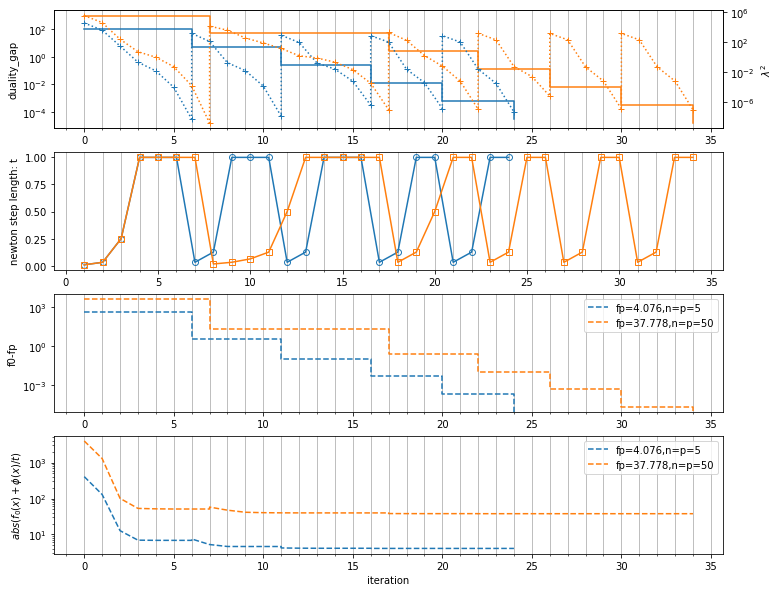

In [83]:
if __name__ == "__main__":
    plot_figure_feasibility_start_convergence(n_s=[5, 50], mu=20, seed=1)

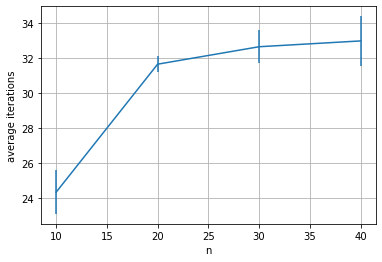

In [84]:
if __name__ == "__main__":
    plot_convergence_speed_vs_n(n_s=[10 * i for i in range(1, 5)], mu=20, n_dial=3)